# Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective:** Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset:** [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/) — ~2.4M product listings with category, price, rating (`stars`), number of reviews, best-seller flag and units bought last month.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

In [ ]:
# The CSV lives in the Part I lab folder 
DATA_PATH = "../lab-eda-univariate/amz_uk_price_prediction_dataset.csv"

df = pd.read_csv(DATA_PATH)
print(df.shape)
display(df.head())

(2443651, 9)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7000,15308,21.9900,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7000,98099,23.9900,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7000,15308,21.9900,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7000,7205,31.9900,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6000,1881,17.9900,False,0,Hi-Fi Speakers


In [3]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB

Missing values per column:
uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64


---
## Part 1: Analyzing Best-Seller Trends Across Product Categories

**Business question:** Is being a best-seller more common in some categories than in others?

### 1. Crosstab Analysis

In [4]:
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab.columns = ["not_bestseller", "bestseller"]   # rename True/False to readable names
display(crosstab.head(10))
print("Number of categories:", crosstab.shape[0])
print(f"Overall best-seller rate: {df['isBestSeller'].mean():.2%}")

,not_bestseller,bestseller
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
Agricultural Equipment & Supplies,8421,109
Alexa Built-In Devices,106,1
Art & Craft Supplies,253,5
Arts & Crafts,9319,230


Number of categories: 296
Overall best-seller rate: 0.33%


In [5]:
# Proportion of best-sellers in each category, sorted from highest to lowest
crosstab["total"] = crosstab["not_bestseller"] + crosstab["bestseller"]
crosstab["bestseller_share"] = crosstab["bestseller"] / crosstab["total"]

bestseller_share = crosstab.sort_values("bestseller_share", ascending=False)
display(bestseller_share.head(15))

,not_bestseller,bestseller,total,bestseller_share
category,,,,
Grocery,9008,556,9564,0.0581
Smart Home Security & Lighting,98,6,104,0.0577
Health & Personal Care,9017,552,9569,0.0577
Mobile Phone Accessories,248,11,259,0.0425
Power & Hand Tools,8353,306,8659,0.0353
"Billiard, Snooker & Pool",241,8,249,0.0321
Pet Supplies,9152,285,9437,0.0302
Home Brewing & Wine Making,239,7,246,0.0285
Mirrors,243,7,250,0.0280


In [6]:
# Categories with zero best-sellers
no_bestsellers = bestseller_share[bestseller_share["bestseller"] == 0]
print(f"{len(no_bestsellers)} categories have no best-sellers at all, e.g.:")
print(no_bestsellers.index[:10].tolist())

36 categories have no best-sellers at all, e.g.:
['Basketball Footwear', 'Barebone PCs', 'Toy Advent Calendars', 'USB Gadgets', 'Vases', 'Motorbike Electrical & Batteries', 'Printer Accessories', 'Hydraulics, Pneumatics & Plumbing', 'Internal TV Tuner & Video Capture Cards', 'Power Supplies']


**Answer:** Yes. The overall best-seller rate is only ~0.33%, but categories like **Grocery (5.8%)**, **Smart Home Security & Lighting (5.8%)**, **Health & Personal Care (5.8%)**, **Mobile Phone Accessories (4.2%)** and **Power & Hand Tools (3.5%)** have best-seller rates more than 10× higher than average. These are everyday, repeat-purchase or practical products. At the other end, 36 categories have no best-sellers at all.

### 2. Statistical Tests

- **H0:** best-seller status is independent of product category.
- **H1:** best-seller status depends on product category.

In [7]:
observed = pd.crosstab(df["category"], df["isBestSeller"])

chi2, p_value, dof, expected = chi2_contingency(observed)
print(f"Chi-square statistic: {chi2:,.2f}")
print(f"Degrees of freedom:   {dof}")
print(f"p-value:              {p_value:.4g}")

if p_value < 0.05:
    print("-> Reject H0: best-seller status is NOT independent of category.")
else:
    print("-> Fail to reject H0.")

Chi-square statistic: 36,540.20
Degrees of freedom:   295
p-value:              0
-> Reject H0: best-seller status is NOT independent of category.


In [8]:
cramers_v = association(observed, method="cramer")
print(f"Cramér's V: {cramers_v:.4f}")

Cramér's V: 0.1223


**Interpretation:** The p-value is essentially 0, so the best-seller distribution is **not** independent of category. However, Cramér's V ≈ **0.12** indicates a **weak** association: with 2.4M rows almost any difference is "significant", but category alone explains only a small part of whether a product becomes a best-seller.

### 3. Visualization — stacked bar chart

With ~300 categories a full chart is unreadable, so we show the 20 categories with the highest best-seller share (as a 100% stacked bar) plus the 20 largest categories by listing count.

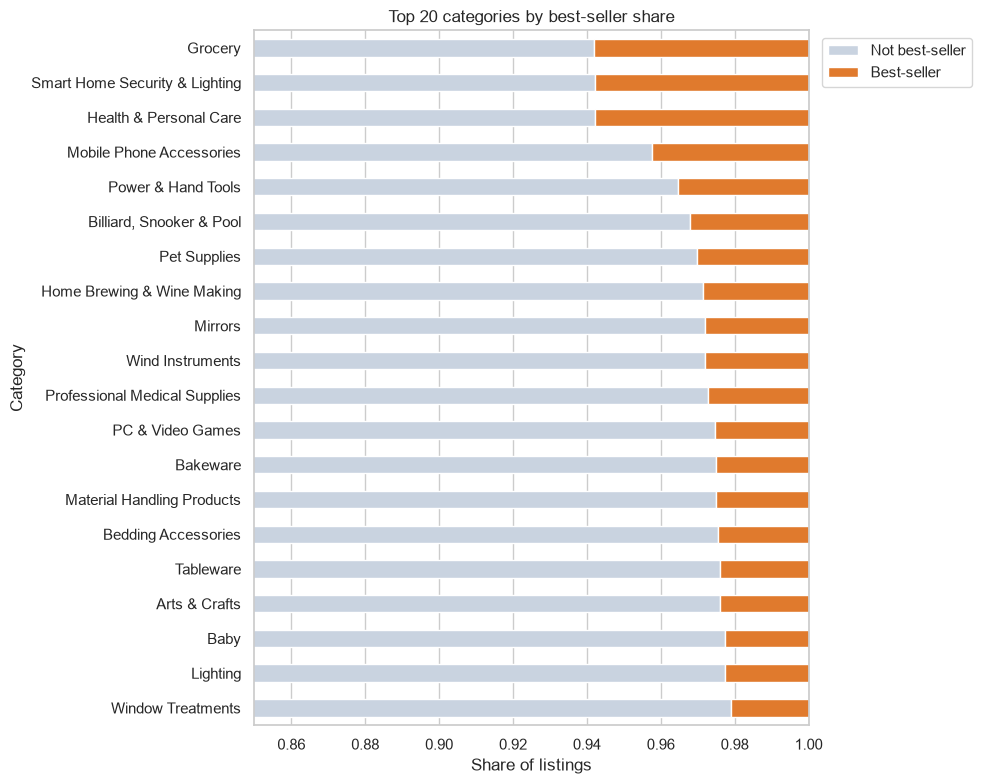

In [9]:
top20_share = bestseller_share.head(20)
props = top20_share[["not_bestseller", "bestseller"]].div(top20_share["total"], axis=0)
props.columns = ["Not best-seller", "Best-seller"]

ax = props.sort_values("Best-seller").plot(
    kind="barh", stacked=True, figsize=(10, 8), color=["#c9d3e0", "#e07a2d"]
)
ax.set_xlabel("Share of listings")
ax.set_ylabel("Category")
ax.set_title("Top 20 categories by best-seller share")
ax.set_xlim(0.85, 1.0)   # zoom in: best-sellers are a small slice
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

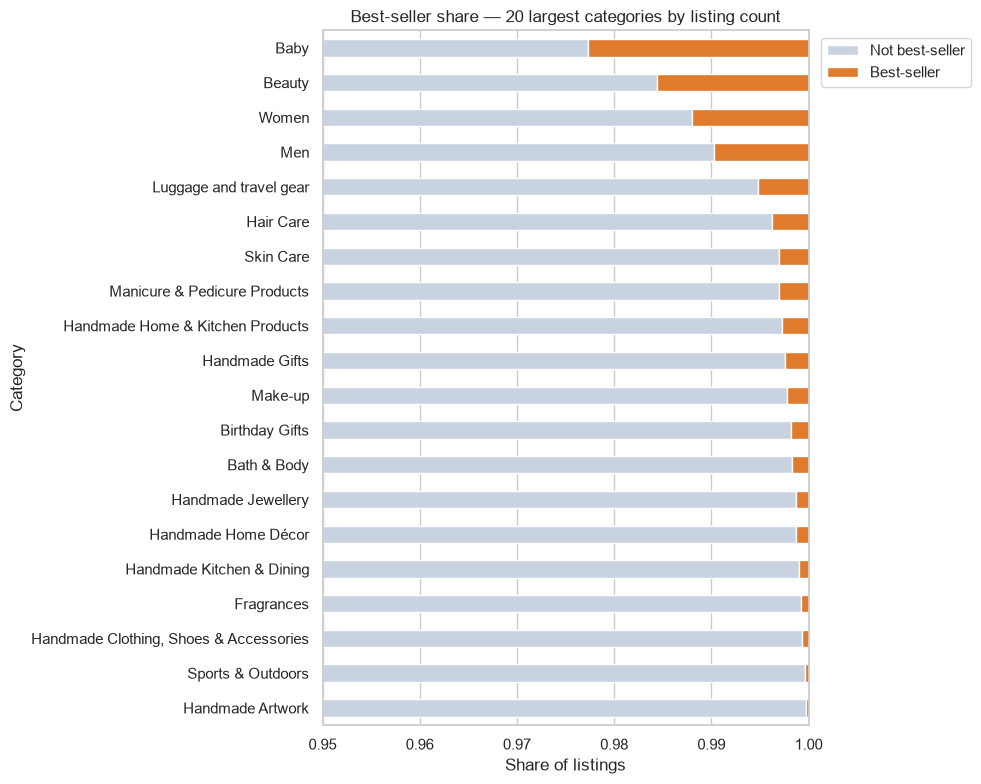

In [10]:
# 100% stacked bar for the 20 largest categories (raw counts would be dominated by Sports & Outdoors)
top20_count = crosstab.sort_values("total", ascending=False).head(20)
props_big = top20_count[["not_bestseller", "bestseller"]].div(top20_count["total"], axis=0)
props_big.columns = ["Not best-seller", "Best-seller"]

ax = props_big.sort_values("Best-seller").plot(
    kind="barh", stacked=True, figsize=(10, 8), color=["#c9d3e0", "#e07a2d"]
)
ax.set_xlabel("Share of listings")
ax.set_ylabel("Category")
ax.set_title("Best-seller share — 20 largest categories by listing count")
ax.set_xlim(0.95, 1.0)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

In the largest categories the best-seller share stays below ~2%, and in Sports & Outdoors (the biggest category by far) it is close to zero — high listing volume does not translate into more best-sellers.

---
## Part 2: Exploring Product Prices and Ratings Across Categories and Brands

### 0. Preliminary step: remove price outliers (IQR method)

In [11]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1 = £{Q1:.2f} | Q3 = £{Q3:.2f} | IQR = £{IQR:.2f}")
print(f"Keep prices between £{lower_bound:.2f} and £{upper_bound:.2f}")

df_no_outliers = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)]

removed = len(df) - len(df_no_outliers)
print(f"Rows removed: {removed:,} ({removed / len(df):.1%})")
print(f"Rows kept:    {len(df_no_outliers):,}")

Q1 = £9.99 | Q3 = £45.99 | IQR = £36.00
Keep prices between £-44.01 and £99.99
Rows removed: 327,688 (13.4%)
Rows kept:    2,115,963


About 13% of listings (everything above ~£100) are flagged as outliers. Prices are heavily right-skewed, so the IQR method cuts the expensive tail rather than errors — worth remembering when reading the results below: **all price findings refer to products under £100**.

### 1. Violin Plots — price by category

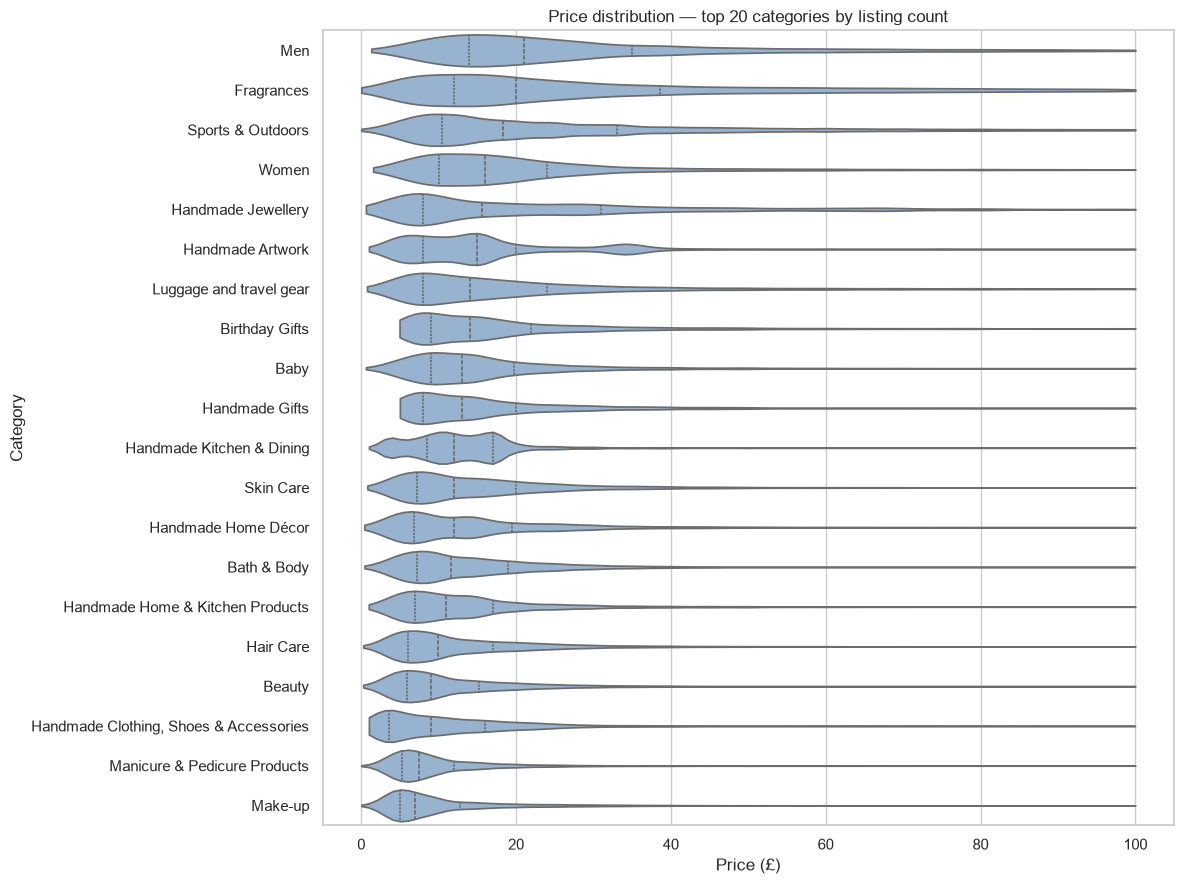

In [12]:
top20_categories = df_no_outliers["category"].value_counts().head(20).index
df_top20 = df_no_outliers[df_no_outliers["category"].isin(top20_categories)]

# order by median price so the chart is easier to read
order = df_top20.groupby("category")["price"].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 9))
sns.violinplot(data=df_top20, y="category", x="price", order=order,
               density_norm="width", cut=0, inner="quartile", color="#8fb3d9")
plt.title("Price distribution — top 20 categories by listing count")
plt.xlabel("Price (£)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [13]:
# Highest median price — ALL categories (no top-N filter)
median_price = df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False)
display(median_price.head(10).to_frame("median_price"))

,median_price
category,
Desktop PCs,74.0000
Boxing Shoes,69.7900
Tablets,69.0000
Graphics Cards,68.5400
Motherboards,67.9200
Made in Italy Handmade,64.0000
Digital Frames,63.9000
Streaming Clients,62.6800
Golf Shoes,62.3900


**Answer:** **Desktop PCs** have the highest median price (£74.00), followed by Boxing Shoes, Tablets, Graphics Cards and Motherboards — mostly tech hardware. Among the 20 largest categories, Sports & Outdoors and gift categories sit at the top, while beauty/make-up categories are concentrated at low prices.

### 2. Bar Charts — average price by category

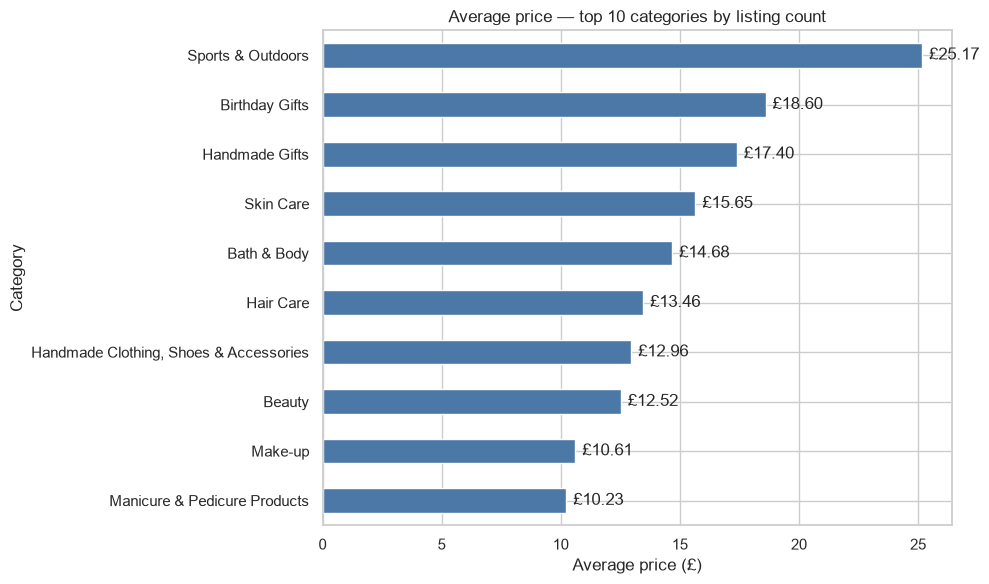

In [14]:
top10_categories = df_no_outliers["category"].value_counts().head(10).index
avg_price_top10 = (
    df_no_outliers[df_no_outliers["category"].isin(top10_categories)]
    .groupby("category")["price"].mean()
    .sort_values()
)

ax = avg_price_top10.plot(kind="barh", figsize=(10, 6), color="#4c78a8")
ax.set_xlabel("Average price (£)")
ax.set_ylabel("Category")
ax.set_title("Average price — top 10 categories by listing count")
for i, v in enumerate(avg_price_top10):
    ax.text(v + 0.3, i, f"£{v:.2f}", va="center")
plt.tight_layout()
plt.show()

In [15]:
# Highest average price — ALL categories (no top-N filter)
mean_price = df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False)
display(mean_price.head(10).to_frame("average_price"))

,average_price
category,
Motherboards,68.7724
Boxing Shoes,67.4178
Desktop PCs,66.9156
Tablets,66.5530
Graphics Cards,65.1035
Digital Frames,60.7451
Streaming Clients,60.2418
Hockey Shoes,60.0948
Computer Cases,58.3399


**Answer:** **Motherboards** command the highest average price (~£68.77), closely followed by Boxing Shoes, Desktop PCs, Tablets and Graphics Cards. Among the 10 most-listed categories, Sports & Outdoors has the highest average (~£25), more than double Make-up and Manicure & Pedicure (~£10).

### 3. Box Plots — ratings by category

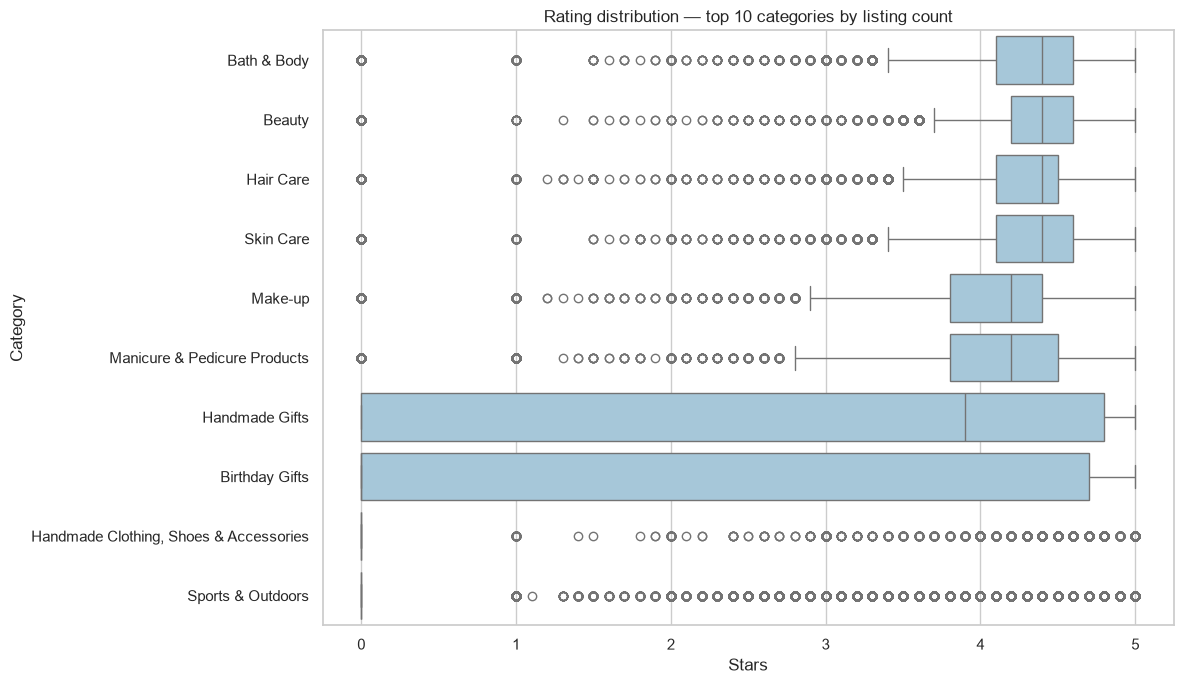

In [16]:
df_top10 = df_no_outliers[df_no_outliers["category"].isin(top10_categories)]
order = df_top10.groupby("category")["stars"].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 7))
sns.boxplot(data=df_top10, y="category", x="stars", order=order, color="#9ecae1")
plt.title("Rating distribution — top 10 categories by listing count")
plt.xlabel("Stars")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [17]:
# Note: stars = 0 means the product has no reviews yet (not a 0-star rating)
share_unrated = (df_no_outliers["stars"] == 0).mean()
print(f"Share of listings with stars = 0 (unrated): {share_unrated:.1%}")
display(df_top10.assign(unrated=df_top10["stars"] == 0)
        .groupby("category")["unrated"].mean().sort_values(ascending=False)
        .to_frame("share_unrated"))

Share of listings with stars = 0 (unrated): 47.3%


,share_unrated
category,
Sports & Outdoors,0.8177
"Handmade Clothing, Shoes & Accessories",0.7646
Birthday Gifts,0.5720
Handmade Gifts,0.4500
Manicure & Pedicure Products,0.1103
Bath & Body,0.0861
Make-up,0.0851
Skin Care,0.0432
Hair Care,0.0321


In [18]:
# Highest median rating — ALL categories (no top-N filter)
median_rating = df_no_outliers.groupby("category")["stars"].median().sort_values(ascending=False)
display(median_rating.head(10).to_frame("median_stars"))

# Same question, only rated products (stars > 0)
median_rating_rated = (df_no_outliers[df_no_outliers["stars"] > 0]
                       .groupby("category")["stars"].median().sort_values(ascending=False))
display(median_rating_rated.head(10).to_frame("median_stars_rated_only"))

,median_stars
category,
Computer Memory,4.7000
"Beer, Wine & Spirits",4.6000
Building & Construction Toys,4.6000
Office Paper Products,4.6000
Kids' Play Figures,4.6000
Laptop Accessories,4.6000
Hobbies,4.6000
Luxury Food & Drink,4.6000
Soft Toys,4.5000


,median_stars_rated_only
category,
Handmade Artwork,5.0000
Made in Italy Handmade,5.0000
Handmade Baby Products,5.0000
"Handmade Clothing, Shoes & Accessories",4.9000
Handmade Kitchen & Dining,4.9000
Birthday Gifts,4.8000
Handmade Home Décor,4.8000
Handmade Gifts,4.8000
Handmade Home & Kitchen Products,4.7000


**Answer:** **Computer Memory** has the highest median rating (4.7 stars). Several categories follow at 4.6 (Kids' Play Figures, Beer/Wine & Spirits, Office Paper Products, Luxury Food & Drink, Building & Construction Toys...).

If we look only at rated products (stars > 0), several handmade categories (Made in Italy Handmade, Handmade Baby Products, Handmade Artwork) reach a median of 5.0.

Important caveat: ~47% of listings have `stars = 0`, which means *no reviews yet*. That is why Sports & Outdoors, Birthday Gifts and Handmade Clothing show a median of 0 in the box plot — most of their listings are unrated, not badly rated.

---
## Part 3: Investigating the Interplay Between Product Prices and Ratings

### 1. Correlation Coefficients

In [19]:
pearson_r, pearson_p = stats.pearsonr(df_no_outliers["price"], df_no_outliers["stars"])
spearman_r, spearman_p = stats.spearmanr(df_no_outliers["price"], df_no_outliers["stars"])

print(f"Pearson  r   = {pearson_r:.4f}  (p = {pearson_p:.3g})")
print(f"Spearman rho = {spearman_r:.4f}  (p = {spearman_p:.3g})")

Pearson  r   = -0.0777  (p = 0)
Spearman rho = -0.0668  (p = 0)


In [20]:
# Same test only on products that actually have a rating
rated = df_no_outliers[df_no_outliers["stars"] > 0]
r_rated, p_rated = stats.pearsonr(rated["price"], rated["stars"])
rho_rated, prho_rated = stats.spearmanr(rated["price"], rated["stars"])
print(f"Rated products only -> Pearson r = {r_rated:.4f} (p = {p_rated:.3g}), "
      f"Spearman rho = {rho_rated:.4f} (p = {prho_rated:.3g})")

Rated products only -> Pearson r = 0.0067 (p = 1.08e-12), Spearman rho = 0.0247 (p = 1.98e-149)


**Answer:** The correlation is **statistically significant but practically negligible**: Pearson r ≈ −0.08 and Spearman ρ ≈ −0.07. With 2.1M rows even tiny correlations get p-values near 0. When we keep only rated products the correlation is essentially zero (r ≈ 0.01). **Price does not predict rating** — cheap products are not rated worse, and expensive ones are not rated better.

### 2. Visualizations

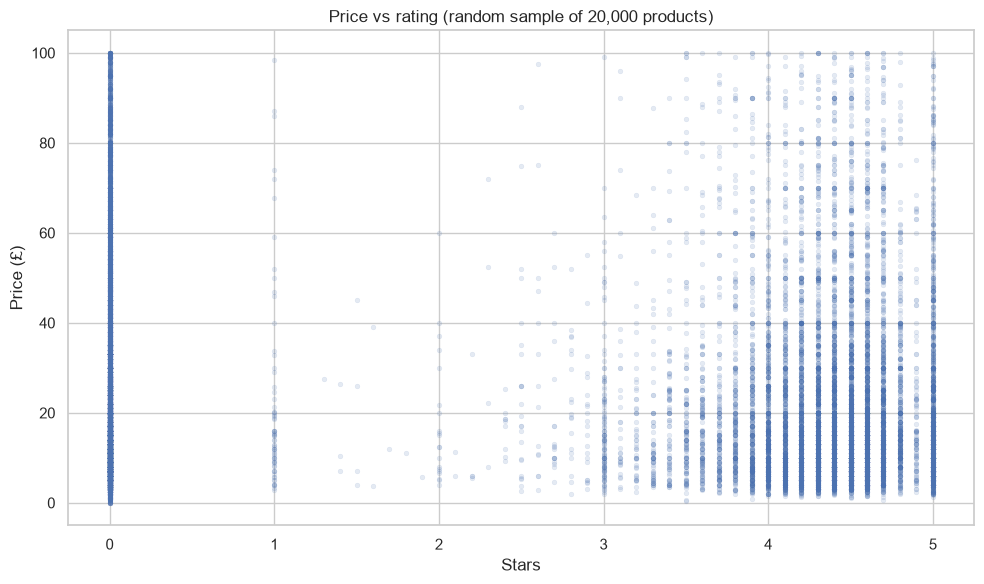

In [21]:
# Scatter plot on a random sample (2M points would just be one big blob)
sample = df_no_outliers.sample(20000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample, x="stars", y="price", alpha=0.15, s=12, edgecolor=None)
plt.title("Price vs rating (random sample of 20,000 products)")
plt.xlabel("Stars")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.show()

**Patterns:** points form vertical stripes because ratings are discrete (0.1 steps). There is a big column at 0 stars (unrated products) across the full price range, and most rated products cluster between 4.0 and 5.0 stars at every price level. No upward or downward trend is visible — consistent with the near-zero correlation.

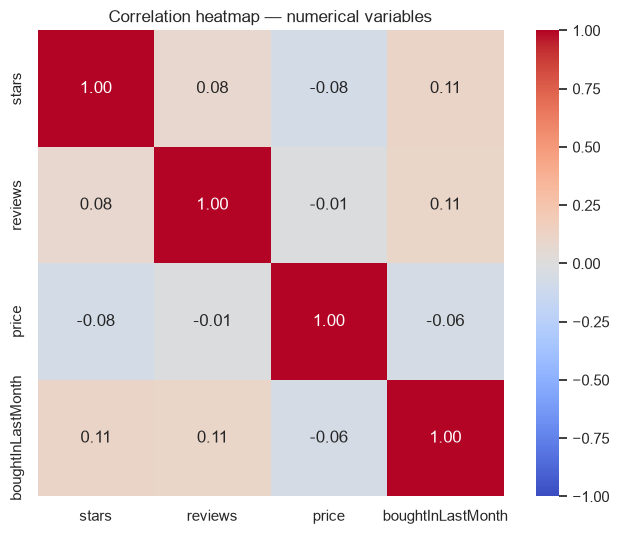

In [22]:
numeric_cols = ["stars", "reviews", "price", "boughtInLastMonth"]
corr_matrix = df_no_outliers[numeric_cols].corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation heatmap — numerical variables")
plt.tight_layout()
plt.show()

All correlations are weak (|r| < 0.12). The strongest relationships are rating ↔ units bought last month (0.11) and reviews ↔ units bought (0.11): products with more social proof sell slightly more. Price is weakly negatively related to sales (−0.06).

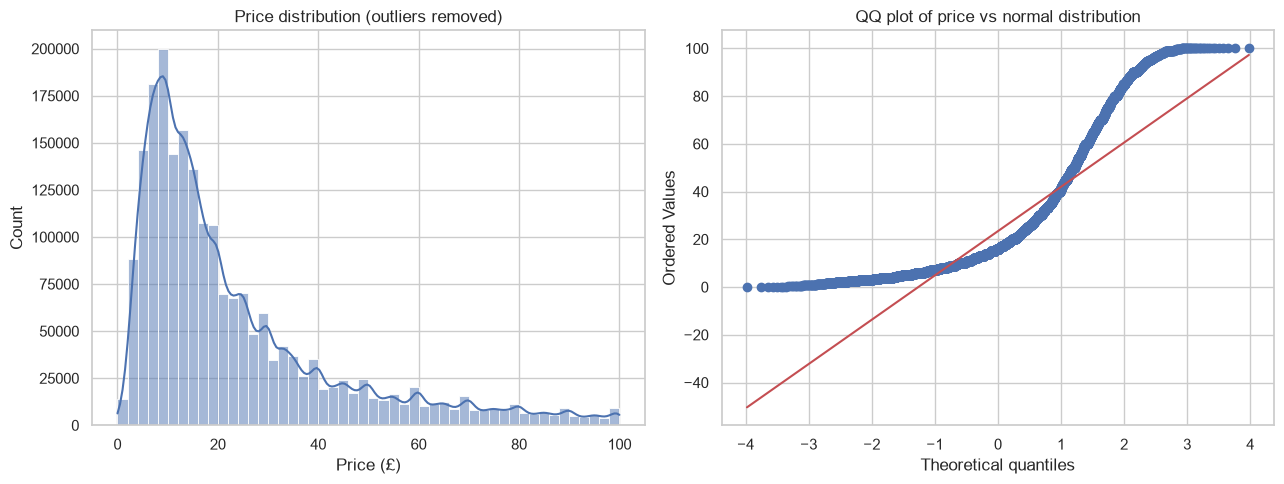

Skewness: 1.64


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df_no_outliers["price"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Price distribution (outliers removed)")
axes[0].set_xlabel("Price (£)")

stats.probplot(sample["price"], dist="norm", plot=axes[1])
axes[1].set_title("QQ plot of price vs normal distribution")

plt.tight_layout()
plt.show()

print(f"Skewness: {df_no_outliers['price'].skew():.2f}")

**Normality:** prices are **not** normally distributed. The histogram is strongly right-skewed (skewness ≈ 1.64), and in the QQ plot the points form an S-shape instead of following the red line: they stay above the line at the low end (prices cannot go below £0), bend sharply upward on the right (long tail of more expensive items) and flatten at the top because of the £100 outlier cut-off. Non-parametric methods (Spearman, medians) or a log transform are more appropriate than tests that assume normality.

---
## Business Report: Key Findings

**1. Best-sellers are concentrated in everyday, practical categories.**
Only 0.33% of listings carry the best-seller badge, but Grocery, Smart Home Security & Lighting and Health & Personal Care reach ~5.8% — about 17× the average. Mobile Phone Accessories and Power & Hand Tools follow. The relationship is statistically significant (χ², p ≈ 0) but weak (Cramér's V ≈ 0.12): *category helps, but it does not decide* best-seller status on its own.
→ *Sellers seeking the badge have better odds in repeat-purchase, utility categories; in other categories success depends more on product-level factors (reviews, price, listing quality).*

**2. Tech hardware sits at the top of the price range.**
After removing outliers (>£100, ~13% of listings), Desktop PCs have the highest median price (£74) and Motherboards the highest average (~£69), with Tablets and Graphics Cards close behind. The highest-volume categories (beauty, make-up, bath & body, handmade) are low-priced (£10–£18 average), while Sports & Outdoors averages ~£25.
→ *High-volume categories compete on price; margin opportunities lie in fewer, higher-ticket tech listings.*

**3. Ratings are high almost everywhere — but half the catalogue is unrated.**
Computer Memory leads with a median of 4.7 stars, and most rated products sit between 4.0 and 5.0. About 47% of listings have no reviews (stars = 0), which pulls down medians for categories like Sports & Outdoors and Birthday Gifts.
→ *Getting the first reviews is the real differentiator; a programme to generate early reviews (e.g. Amazon Vine) is likely to matter more than small rating differences.*

**4. Price does not drive ratings.**
Price–rating correlation is negligible (r ≈ −0.08; ≈ 0.01 among rated products). Ratings and review counts are only weakly linked to units sold (r ≈ 0.11).
→ *Charging more does not hurt customer satisfaction, and cutting prices will not buy better ratings. Pricing can be set on cost/competition, not on fear of worse reviews.*

**5. Prices are not normal.**
Prices are right-skewed, so medians and non-parametric tests should be preferred in future pricing analysis, or prices should be log-transformed before modelling.

**Limitations:** the dataset is a single snapshot; the IQR filter removes all items above £100 (so premium-product behaviour is excluded); `stars = 0` mixes "unrated" with the rating scale; and correlation does not imply causation.